# 05 · Midterm figures and tables (course: Multimodal Deep Learning)
Figures and tables for the midterm report. Reads only data/processed and data/interim.
New EDA uses train + validation periods only (days 19–52); the test period stays closed.

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Clone or update the project repository
import os
from google.colab import userdata
token = userdata.get('GH_TOKEN')
REPO = '/content/tevzi'
if not os.path.exists(REPO):
    !git clone -q https://{token}@github.com/emirsalihoglu/tevzi.git {REPO}
else:
    !git -C {REPO} pull -q
!git -C {REPO} log --oneline -1

2c150e0 (HEAD -> main, origin/main, origin/HEAD) Add notebook 04: stage 3.0-3.3 (protocol, baselines, preprocessing, GBM)


In [3]:
# Make the package importable and prepare Drive folders
import sys
from pathlib import Path
sys.path.insert(0, f'{REPO}/src')
DRIVE = Path('/content/drive/MyDrive/Tevzi')
for sub in ['data/raw', 'data/interim', 'data/processed',
            'results/models', 'results/figures', 'results/tables']:
    (DRIVE / sub).mkdir(parents=True, exist_ok=True)
import tevzi
print('tevzi package:', tevzi.__file__)
print('Drive folder:', DRIVE)

tevzi package: /content/tevzi/src/tevzi/__init__.py
Drive folder: /content/drive/MyDrive/Tevzi


In [4]:
# Inspect processed and interim files: schema and row counts, no data loaded
import pyarrow.parquet as pq

def show_dir(folder):
    for p in sorted(folder.glob('*')):
        size = p.stat().st_size / 1e6
        if p.suffix == '.parquet':
            f = pq.ParquetFile(p)
            names = f.schema_arrow.names
            print(f'{p.name}: {f.metadata.num_rows:,} rows, {len(names)} cols, {size:.1f} MB')
            print('    ', names[:25], '...' if len(names) > 25 else '')
        else:
            print(f'{p.name}: {size:.2f} MB')

PROC, INTERIM = DRIVE / 'data/processed', DRIVE / 'data/interim'
print('=== processed'); show_dir(PROC)
print('\n=== interim'); show_dir(INTERIM)

=== processed
jobs_flags.parquet: 1,055,501 rows, 15 cols, 40.7 MB
     ['job_name', 'user', 'status', 'submit_time', 'end_time', 'first_start', 'n_tasks', 'req_gpu_total', 'req_cpu_total', 'req_mem_total', 'R2_cpu_only', 'm2_arrival', 'm2_occupancy', 'model', 'first_rule'] 
m1_features.parquet: 714,273 rows, 47 cols, 77.7 MB
     ['job_name', 'main_plan_gpu', 'main_plan_cpu', 'main_plan_mem', 'main_inst_num', 'req_gpu_total', 'req_cpu_total', 'req_mem_total', 'main_gpu_type', 'gpu_fractional', 'mem_per_gpu', 'cpu_per_gpu', 'n_tasks', 'has_ps', 'has_evaluator', 'n_ps_inst', 'total_inst', 'main_task', 'user', 'workload', 'workload_missing', 'grp_rt_n', 'grp_rt_mean', 'grp_rt_std', 'grp_rt_last'] ...
m2_capacities.json: 0.00 MB
m2_grid.parquet: 19,858 rows, 28 cols, 2.6 MB
     ['t', 'arr_count', 'arr_gpu', 'occ_gpu', 'occ_cpu', 'occ_mem', 'pressure', 'use_gpu', 'ALL:pool_occ', 'ALL:pool_pressure', 'ALL:pool_arr_gpu', 'ALL:pool_use_gpu', 'P100:pool_occ', 'P100:pool_pressure', 'P100:pool_

In [5]:
# Figure helper: one style for all figures, saved as results/figures/F##_name.png
import matplotlib.pyplot as plt
FIG = DRIVE / 'results/figures'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
    'axes.grid': True, 'grid.alpha': 0.3,
    'axes.spines.top': False, 'axes.spines.right': False,
})

def save_fig(fig, fid, name):
    path = FIG / f'F{fid:02d}_{name}.png'
    fig.savefig(path, bbox_inches='tight')
    print('saved', path.name)

In [6]:
# T3: matching statistics — does every model job have every modality, and are they aligned in time?
import numpy as np, pandas as pd, pyarrow.parquet as pq

jf = pd.read_parquet(PROC / 'jobs_flags.parquet', columns=['job_name', 'submit_time', 'model'])
tg = pd.read_parquet(PROC / 'targets.parquet',
                     columns=['job_name', 'period', 'submit_day', 'purged', 'has_usage'])
m1 = pd.read_parquet(PROC / 'm1_features.parquet', columns=['job_name', 'grp_rt_n', 'usr_rt_n'])
sn = pd.read_parquet(PROC / 'm2_snapshots.parquet', columns=['job_name', 'submit', 'pool_key', 'k_last'])
grid_t = pd.read_parquet(PROC / 'm2_grid.parquet', columns=['t'])['t'].to_numpy()
grid_cols = pq.ParquetFile(PROC / 'm2_grid.parquet').schema_arrow.names

# 1) Keys: unique in every table, and exactly the model-set jobs everywhere
model_jobs = set(jf.loc[jf['model'].astype(bool), 'job_name'])
print(f'model jobs: {len(model_jobs):,}')
for name, df in [('targets', tg), ('m1', m1), ('m2_snapshots', sn)]:
    print(f'  {name:13s} rows {len(df):,} | unique key: {df.job_name.is_unique} '
          f'| same job set: {set(df.job_name) == model_jobs}')

# 2) Time alignment: snapshot time = submission time; k_last = grid step just before submission
d = sn.merge(jf[['job_name', 'submit_time']], on='job_name', how='left')
print('\nsnapshot submit == job submit_time:', bool(np.allclose(d['submit'], d['submit_time'])))
k = d['k_last'].to_numpy()
print(f'k_last range: {k.min()} .. {k.max()} (grid has {len(grid_t):,} steps, '
      f'step {np.diff(grid_t[:2])[0]:.0f} s)')
gap = d['submit'].to_numpy() - grid_t[k]
print('submit - t[k_last] in seconds:')
print(pd.Series(gap).describe(percentiles=[0.01, 0.5, 0.99]).round(1).to_string())

# 3) Pools: every job's pool has its columns in the grid
pools = sn['pool_key'].value_counts()
print('\npool_key counts:'); print(pools.to_string())
missing = [p for p in pools.index if f'{p}:pool_occ' not in grid_cols]
print('pools without grid columns:', missing)

# 4) Coverage per period (counts are descriptive; no target values are used)
t3 = (tg.merge(m1, on='job_name').merge(sn[['job_name', 'k_last']], on='job_name'))
t3['m2_full_window'] = t3['k_last'] >= 23          # 24 past steps available
t3['grp_history'] = t3['grp_rt_n'].fillna(0) > 0
t3['usr_history'] = t3['usr_rt_n'].fillna(0) > 0
order = t3.groupby('period')['submit_day'].min().sort_values().index
agg = (t3.groupby('period')
         .agg(jobs=('job_name', 'size'), m2_full_window=('m2_full_window', 'sum'),
              usage_label=('has_usage', 'sum'), grp_history=('grp_history', 'sum'),
              usr_history=('usr_history', 'sum'), purged=('purged', 'sum'))
         .reindex(order))
agg.loc['total'] = agg.sum()
for c in ['m2_full_window', 'usage_label', 'grp_history', 'usr_history', 'purged']:
    agg[c + '_%'] = (100 * agg[c] / agg['jobs']).round(1)
print(); print(agg.to_string())
agg.to_csv(DRIVE / 'results/tables/midterm_T3_matching.csv')
print('saved midterm_T3_matching.csv')

model jobs: 714,273
  targets       rows 714,273 | unique key: True | same job set: True
  m1            rows 714,273 | unique key: True | same job set: True
  m2_snapshots  rows 714,273 | unique key: True | same job set: True

snapshot submit == job submit_time: True
k_last range: 160 .. 19855 (grid has 19,858 steps, step 300 s)
submit - t[k_last] in seconds:
count    714273.0
mean        150.5
std          86.7
min           1.0
1%            4.0
50%         151.0
99%         297.0
max         300.0

pool_key counts:
pool_key
ALL        456357
T4         183406
P100        49366
V100        16460
V100M32      8684
pools without grid columns: []

          jobs  m2_full_window  usage_label  grp_history  usr_history  purged  m2_full_window_%  usage_label_%  grp_history_%  usr_history_%  purged_%
period                                                                                                                                                
warmup  123831          123831         150

log_run_time == log1p(run_time): True
T4: 34,343 candidates, pool_pressure in [0.000, 0.009], median wait 3 s -> 96abd92db1f26f617307b31f
V100: 301 candidates, pool_pressure in [0.457, 60.000], median wait 116 s -> 6c21ae223da5fb62fcba877a
saved F07_matching_example.png


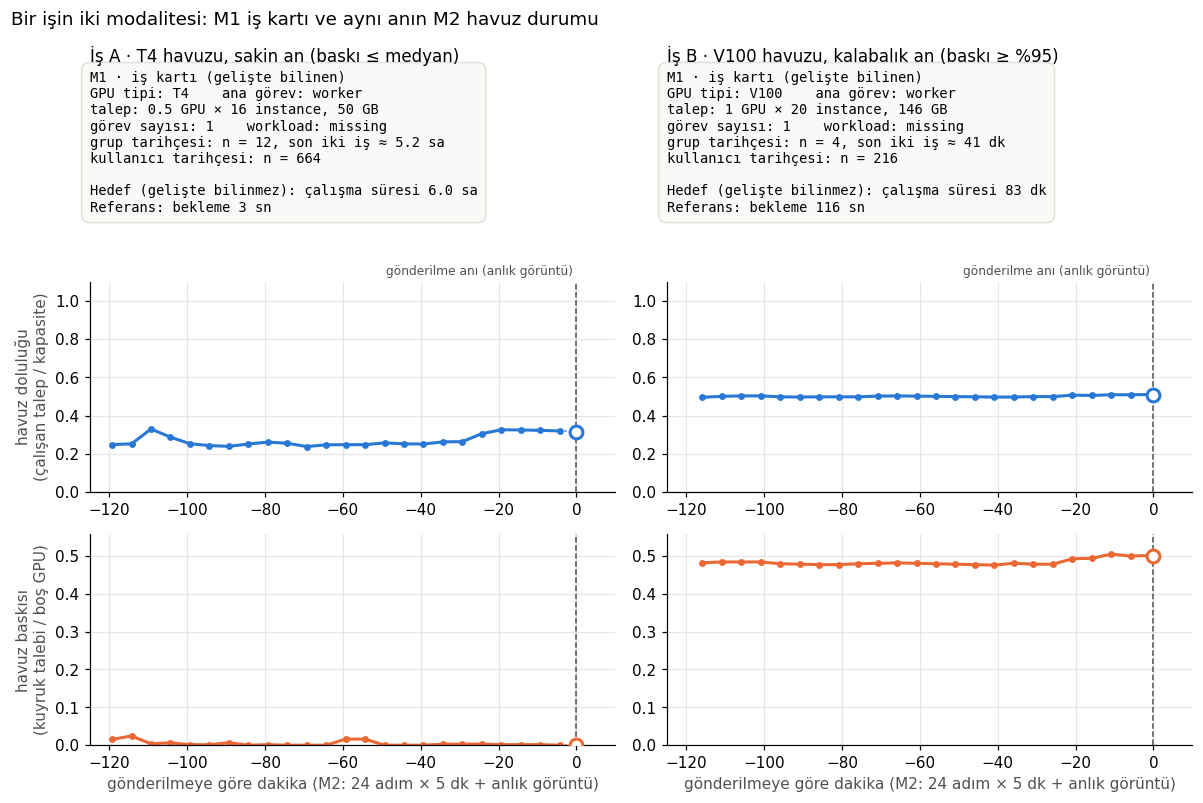

İş A · T4 havuzu, sakin an (baskı ≤ medyan) | 96abd92db1f26f617307b31f | submit 2141877.0 | k_last 5491 | snapshot occ/pressure 0.317 0.0
İş B · V100 havuzu, kalabalık an (baskı ≥ %95) | 6c21ae223da5fb62fcba877a | submit 2964571.0 | k_last 8234 | snapshot occ/pressure 0.51 0.501


In [7]:
# F07: matching evidence — a calm T4 job and a busy V100 job: M1 card + M2 window, submission marked
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

C_OCC, C_PRES = '#2a78d6', '#eb6834'          # categorical slots 1-2 (validated palette)
INK2, MUTED, PANEL, EDGE = '#52514e', '#898781', '#f9f9f7', '#e1e0d9'

tg = pd.read_parquet(PROC / 'targets.parquet',
                     columns=['job_name', 'period', 'purged', 'run_time', 'log_run_time', 'wait_time'])
sn = pd.read_parquet(PROC / 'm2_snapshots.parquet',
                     columns=['job_name', 'submit', 'pool_key', 'k_last', 'pool_occ', 'pool_pressure'])
m1c = ['job_name', 'main_gpu_type', 'main_task', 'main_plan_gpu', 'main_plan_mem', 'main_inst_num',
       'n_tasks', 'workload', 'grp_rt_n', 'grp_rt_last2', 'usr_rt_n']
m1 = pd.read_parquet(PROC / 'm1_features.parquet', columns=m1c)
grid = pd.read_parquet(PROC / 'm2_grid.parquet')
print('log_run_time == log1p(run_time):', bool(np.allclose(tg.log_run_time, np.log1p(tg.run_time))))

# Candidates: train/val, not purged, with group history (so the M1 card carries history)
J = (tg[tg.period.isin(['train', 'val']) & ~tg.purged.astype(bool)]
       .merge(sn, on='job_name').merge(m1, on='job_name'))
J = J[J.grp_rt_n.fillna(0) > 0]

def pick(pool, lo_q, hi_q):
    """Representative, not cherry-picked: the job whose wait is closest to the subset median."""
    s = J[J.pool_key == pool]
    lo, hi = s.pool_pressure.quantile([lo_q, hi_q])
    s = s[s.pool_pressure.between(lo, hi)]
    med = s.wait_time.median()
    r = s.iloc[int(np.argmin((s.wait_time - med).abs().to_numpy()))]
    print(f'{pool}: {len(s):,} candidates, pool_pressure in [{lo:.3f}, {hi:.3f}], '
          f'median wait {med:.0f} s -> {r.job_name}')
    return r

def fmt(sec):
    sec = float(sec)
    return f'{sec:.0f} sn' if sec < 120 else f'{sec/60:.0f} dk' if sec < 7200 else f'{sec/3600:.1f} sa'

def card(r):
    return '\n'.join([
        'M1 · iş kartı (gelişte bilinen)',
        f'GPU tipi: {r.main_gpu_type}    ana görev: {r.main_task}',
        f'talep: {r.main_plan_gpu/100:g} GPU × {r.main_inst_num:.0f} instance, {r.main_plan_mem:.0f} GB',
        f'görev sayısı: {r.n_tasks:.0f}    workload: {r.workload}',
        f'grup tarihçesi: n = {r.grp_rt_n:g}, son iki iş ≈ {fmt(np.expm1(r.grp_rt_last2))}',
        f'kullanıcı tarihçesi: n = {r.usr_rt_n:g}',
        '',
        f'Hedef (gelişte bilinmez): çalışma süresi {fmt(r.run_time)}',
        f'Referans: bekleme {fmt(r.wait_time)}',
    ])

jobs = [('İş A · T4 havuzu, sakin an (baskı ≤ medyan)', pick('T4', 0.0, 0.5)),
        ('İş B · V100 havuzu, kalabalık an (baskı ≥ %95)', pick('V100', 0.95, 1.0))]

t = grid['t'].to_numpy()
fig, axes = plt.subplots(3, 2, figsize=(11, 7.4), gridspec_kw={'height_ratios': [0.8, 1, 1]})
rows = [('pool_occ', C_OCC, 'havuz doluluğu\n(çalışan talep / kapasite)'),
        ('pool_pressure', C_PRES, 'havuz baskısı\n(kuyruk talebi / boş GPU)')]
for j, (title, r) in enumerate(jobs):
    axes[0, j].axis('off')
    axes[0, j].set_title(title, loc='left', fontsize=11)
    axes[0, j].text(0, 1, card(r), va='top', fontsize=9, family='DejaVu Sans Mono',
                    bbox=dict(boxstyle='round,pad=0.6', fc=PANEL, ec=EDGE))
    ks = np.arange(int(r.k_last) - 23, int(r.k_last) + 1)
    x = (t[ks] - r.submit) / 60
    for i, (ch, col, lab) in enumerate(rows, start=1):
        ax = axes[i, j]
        y = grid[f'{r.pool_key}:{ch}'].to_numpy()[ks]
        ax.plot(x, y, color=col, lw=2, marker='o', ms=3.5)
        ax.plot([x[-1], 0], [y[-1], r[ch]], color=col, lw=1.2, ls=':')
        ax.scatter([0], [r[ch]], s=70, facecolor='white', edgecolor=col, lw=2, zorder=3)
        ax.axvline(0, color=INK2, lw=1, ls='--')
        ax.set_xlim(-125, 10)
        if j == 0:
            ax.set_ylabel(lab, color=INK2)
        if i == 1:
            ax.text(-1, 1.02, 'gönderilme anı (anlık görüntü)', transform=ax.get_xaxis_transform(),
                    ha='right', va='bottom', fontsize=8, color=INK2)
        if i == 2:
            ax.set_xlabel('gönderilmeye göre dakika (M2: 24 adım × 5 dk + anlık görüntü)', color=INK2)
for i in (1, 2):                                    # same y-scale per channel, so A and B compare
    top = 1.1 * max(axes[i, 0].get_ylim()[1], axes[i, 1].get_ylim()[1], 1.0 if i == 1 else 0)
    for j in (0, 1):
        axes[i, j].set_ylim(0, top)
fig.suptitle('Bir işin iki modalitesi: M1 iş kartı ve aynı anın M2 havuz durumu', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 7, 'matching_example')
plt.show()
for title, r in jobs:
    print(title, '|', r.job_name, '| submit', r.submit, '| k_last', r.k_last,
          '| snapshot occ/pressure', round(float(r.pool_occ), 3), round(float(r.pool_pressure), 3))

jobs (train+val, not purged): 369,675 | with usage label: 358,322 (96.9%)
saved F03_target_distributions.png


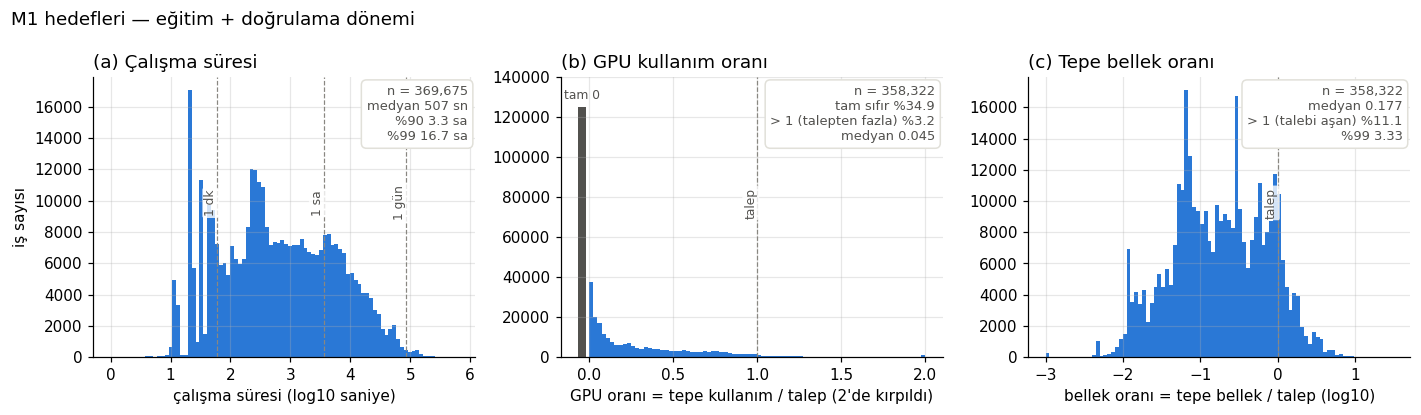

In [8]:
# F03: M1 target distributions (train + validation): run time, GPU ratio, peak memory ratio
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BLUE, INK2, MUTED = '#2a78d6', '#52514e', '#898781'
tg = pd.read_parquet(PROC / 'targets.parquet',
                     columns=['job_name', 'period', 'purged', 'run_time', 'gpu_ratio', 'mem_ratio', 'has_usage'])
E = tg[tg.period.isin(['train', 'val']) & ~tg.purged.astype(bool)]
U = E[E.has_usage.astype(bool)]
print(f'jobs (train+val, not purged): {len(E):,} | with usage label: {len(U):,} ({100*len(U)/len(E):.1f}%)')

def note(ax, lines):
    ax.text(0.98, 0.97, '\n'.join(lines), transform=ax.transAxes, ha='right', va='top', fontsize=8.5,
            color=INK2, bbox=dict(boxstyle='round,pad=0.4', fc='white', ec='#e1e0d9'))

def vlabel(ax, x, text):
    ax.text(x, 0.55, text, transform=ax.get_xaxis_transform(), rotation=90, ha='right', va='center',
            fontsize=8, color=INK2, bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

# (a) run time on log10 seconds
ax = axes[0]
x = np.log10(E.run_time.clip(lower=1))
ax.hist(x, bins=90, color=BLUE)
for sec, lab in [(60, '1 dk'), (3600, '1 sa'), (86400, '1 gün')]:
    ax.axvline(np.log10(sec), color=MUTED, ls='--', lw=0.8)
    vlabel(ax, np.log10(sec), lab)
q = E.run_time.quantile([0.5, 0.9, 0.99])
note(ax, [f'n = {len(E):,}', f'medyan {q[0.5]:.0f} sn', f'%90 {q[0.9]/3600:.1f} sa', f'%99 {q[0.99]/3600:.1f} sa'])
ax.set_xlabel('çalışma süresi (log10 saniye)'); ax.set_ylabel('iş sayısı'); ax.set_title('(a) Çalışma süresi', loc='left')

# (b) GPU ratio: exact zeros shown as their own bar, display clipped at 2
ax = axes[1]
g = U.gpu_ratio
zero, over = (g == 0).mean(), (g > 1).mean()
ax.hist(g[(g > 0)].clip(upper=2), bins=np.linspace(0, 2, 81), color=BLUE)
ax.bar(-0.04, (g == 0).sum(), width=0.05, color=INK2)
ax.axvline(1, color=MUTED, ls='--', lw=0.8)
ax.set_ylim(0, (g == 0).sum() * 1.12)
ax.text(-0.04, (g == 0).sum() * 1.02, 'tam 0', fontsize=8, color=INK2, ha='center', va='bottom')
vlabel(ax, 1, 'talep')
note(ax, [f'n = {len(U):,}', f'tam sıfır %{100*zero:.1f}', f'> 1 (talepten fazla) %{100*over:.1f}', f'medyan {g.median():.3f}'])
ax.set_xlabel('GPU oranı = tepe kullanım / talep (2\'de kırpıldı)'); ax.set_title('(b) GPU kullanım oranı', loc='left')

# (c) peak memory ratio on log10 scale
ax = axes[2]
m = U.mem_ratio
ax.hist(np.log10(m.clip(lower=1e-3)), bins=90, color=BLUE)
ax.axvline(0, color=MUTED, ls='--', lw=0.8)
vlabel(ax, 0, 'talep')
note(ax, [f'n = {len(U):,}', f'medyan {m.median():.3f}', f'> 1 (talebi aşan) %{100*(m > 1).mean():.1f}',
          f'%99 {m.quantile(0.99):.2f}'])
ax.set_xlabel('bellek oranı = tepe bellek / talep (log10)'); ax.set_title('(c) Tepe bellek oranı', loc='left')

fig.suptitle('M1 hedefleri — eğitim + doğrulama dönemi', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 3, 'target_distributions')
plt.show()

In [10]:
# T7: summary statistics (train + validation) for targets, numeric M1 features and M2 snapshot channels
import numpy as np, pandas as pd

keep = lambda df: df[df.job_name.isin(E.job_name)]
tgt = keep(pd.read_parquet(PROC / 'targets.parquet',
                           columns=['job_name', 'run_time', 'log_run_time', 'wait_time', 'gpu_ratio', 'mem_ratio']))
m1n = keep(pd.read_parquet(PROC / 'm1_features.parquet'))
m1n = m1n[['job_name'] + [c for c in m1n.columns if c != 'job_name' and pd.api.types.is_numeric_dtype(m1n[c])]]
snp = keep(pd.read_parquet(PROC / 'm2_snapshots.parquet')).drop(columns=['submit', 'pool_key', 'k_last'])

def describe(df, modality):
    x = df.drop(columns='job_name').copy()
    for c in x.columns:                      # booleans -> 0/1 floats (mean = share)
        if x[c].dtype.kind == 'b' or str(x[c].dtype) == 'boolean':
            x[c] = x[c].to_numpy(dtype=float, na_value=np.nan)
    out = pd.DataFrame({
        'modality': modality, 'n': x.notna().sum(), 'missing_%': (100 * x.isna().mean()).round(1),
        'mean': x.mean(), 'std': x.std(), 'min': x.min(), 'q25': x.quantile(0.25),
        'median': x.median(), 'q75': x.quantile(0.75), 'q99': x.quantile(0.99), 'max': x.max()})
    return out

T7 = pd.concat([describe(tgt, 'target'), describe(m1n, 'M1'), describe(snp, 'M2 snapshot')])
T7.index.name = 'feature'
T7.to_csv(DRIVE / 'results/tables/midterm_T7_summary_stats.csv')
print(f'T7: {len(T7)} rows saved -> midterm_T7_summary_stats.csv')
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200):
    print(T7.drop(columns=['min', 'q25', 'q75']).to_string())

T7: 58 rows saved -> midterm_T7_summary_stats.csv
                        modality       n  missing_%      mean       std    median       q99       max
feature                                                                                              
run_time                  target  369675          0      4831  1.51e+04       507 6.027e+04 6.264e+05
log_run_time              target  369675          0     6.406     2.185      6.23     11.01     13.35
wait_time                 target  369675          0     402.3      4299         7      8331 5.543e+05
gpu_ratio                 target  358322        3.1    0.2174     0.411     0.045     1.349        70
mem_ratio                 target  358322        3.1    0.4283     0.745     0.177     3.327     30.45
main_plan_gpu                 M1  369675          0     67.38     55.02        50       200       800
main_plan_cpu                 M1  369675          0     698.8     462.5       600      2000      9000
main_plan_mem                 M1

saved F04_requests_representation.png


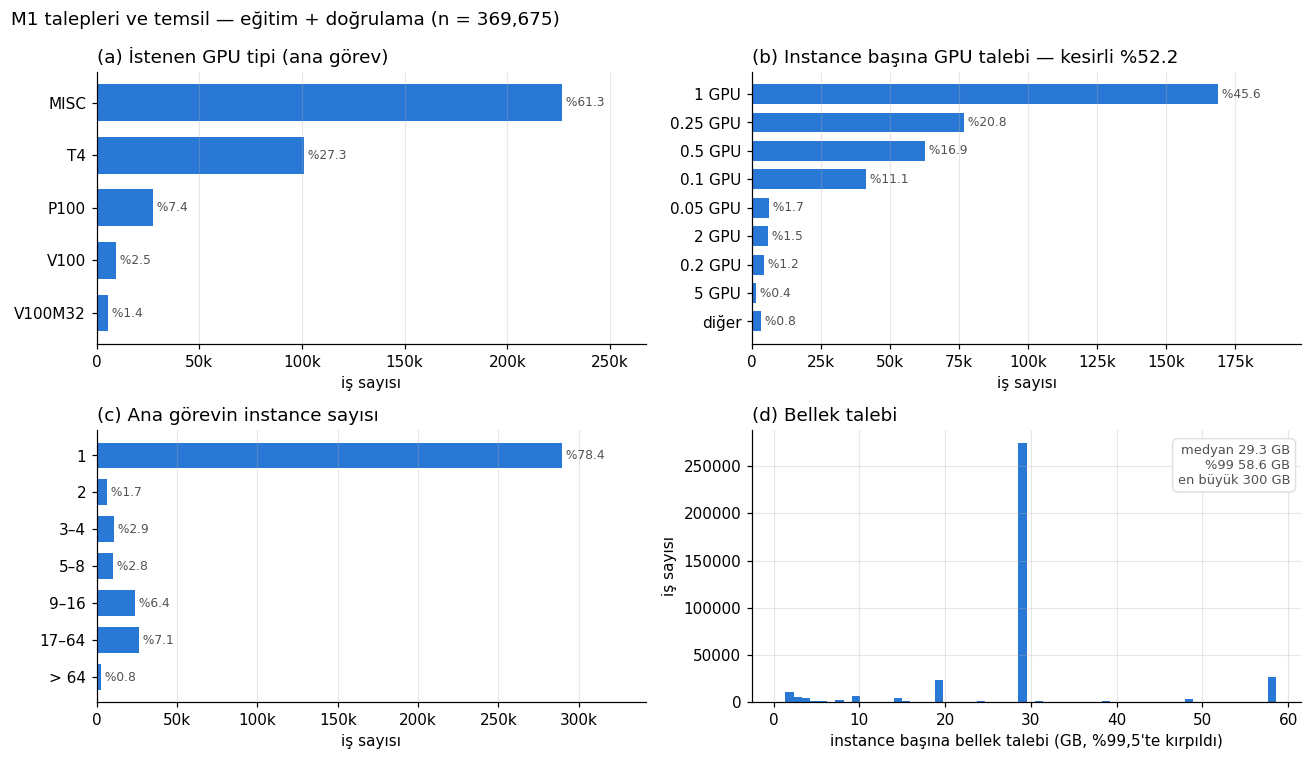

In [14]:
# F04: M1 requests and representation (train + validation): GPU type, GPU per instance, instances, memory
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BLUE, INK2 = '#2a78d6', '#52514e'
r = pd.read_parquet(PROC / 'm1_features.parquet',
                    columns=['job_name', 'main_gpu_type', 'main_plan_gpu', 'main_inst_num', 'main_plan_mem', 'gpu_fractional'])
r = r[r.job_name.isin(E.job_name)]
n = len(r)

def hbar(ax, counts, title, xlabel='iş sayısı'):
    counts = counts.iloc[::-1]
    ax.barh(counts.index.astype(str), counts.values, color=BLUE, height=0.7)
    for y, v in enumerate(counts.values):
        ax.text(v, y, f' %{100*v/n:.1f}', va='center', fontsize=8, color=INK2)
    ax.set_xlim(0, counts.max() * 1.18); ax.set_xlabel(xlabel); ax.set_title(title, loc='left')
    ax.grid(axis='y', visible=False)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k' if v >= 1000 else f'{v:.0f}'))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
hbar(axes[0, 0], r.main_gpu_type.astype(str).value_counts(), '(a) İstenen GPU tipi (ana görev)')

g = (r.main_plan_gpu / 100).round(2)
top = g.value_counts().head(8)
gc = pd.concat([top, pd.Series({'diğer': n - top.sum()})])
gc.index = [f'{v:g} GPU' if v != 'diğer' else v for v in gc.index]
hbar(axes[0, 1], gc, f'(b) Instance başına GPU talebi — kesirli %{100*r.gpu_fractional.mean():.1f}')

bins = [0, 1, 2, 4, 8, 16, 64, np.inf]
labels = ['1', '2', '3–4', '5–8', '9–16', '17–64', '> 64']
ic = pd.cut(r.main_inst_num, bins=bins, labels=labels).value_counts().reindex(labels)
hbar(axes[1, 0], ic, '(c) Ana görevin instance sayısı')

ax = axes[1, 1]
mem = r.main_plan_mem
ax.hist(mem.clip(upper=mem.quantile(0.995)), bins=60, color=BLUE)
ax.set_xlabel('instance başına bellek talebi (GB, %99,5\'te kırpıldı)'); ax.set_ylabel('iş sayısı')
ax.set_title('(d) Bellek talebi', loc='left')
ax.text(0.98, 0.95, f'medyan {mem.median():.1f} GB\n%99 {mem.quantile(0.99):.1f} GB\nen büyük {mem.max():.0f} GB',
        transform=ax.transAxes, ha='right', va='top', fontsize=8.5, color=INK2,
        bbox=dict(boxstyle='round,pad=0.4', fc='white', ec='#e1e0d9'))

fig.suptitle(f'M1 talepleri ve temsil — eğitim + doğrulama (n = {n:,})', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 4, 'requests_representation')
plt.show()

levels: main_task 10 | workload 10
saved F15_categorical_features.png


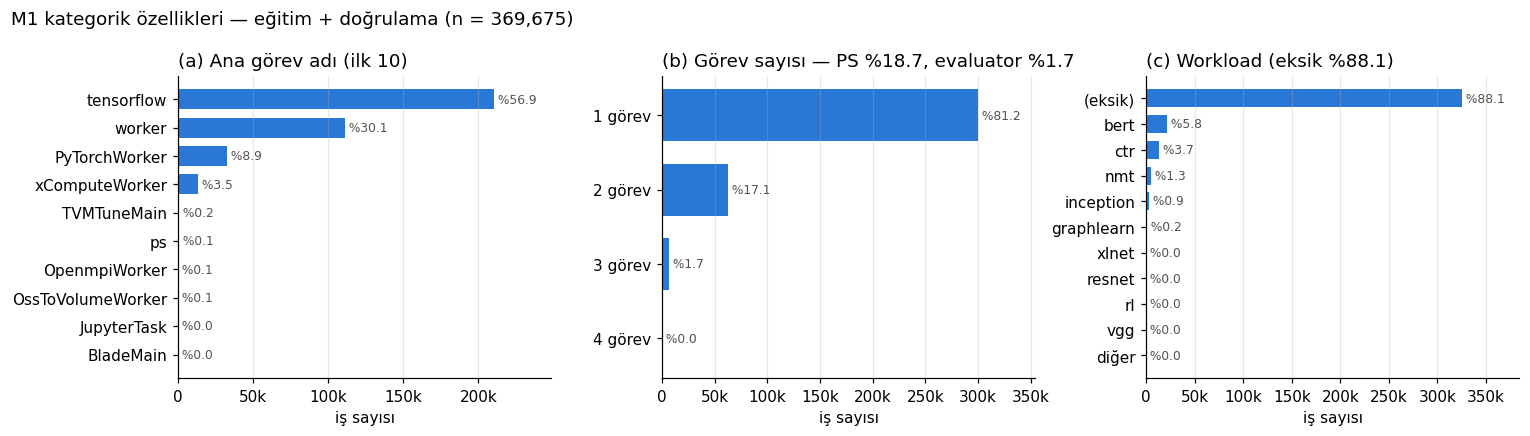

In [15]:
# F15: M1 categorical features (train + validation): main task, number of tasks, workload
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

c = pd.read_parquet(PROC / 'm1_features.parquet',
                    columns=['job_name', 'main_task', 'n_tasks', 'has_ps', 'has_evaluator', 'workload', 'workload_missing'])
c = c[c.job_name.isin(E.job_name)]
n = len(c)
print('levels: main_task', c.main_task.nunique(), '| workload', c.workload.nunique())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
hbar(axes[0], c.main_task.astype(str).value_counts().head(10), '(a) Ana görev adı (ilk 10)')
nt = c.n_tasks.astype(int).value_counts().sort_index()
nt.index = [f'{k} görev' for k in nt.index]
hbar(axes[1], nt, f'(b) Görev sayısı — PS %{100*c.has_ps.mean():.1f}, evaluator %{100*c.has_evaluator.mean():.1f}')
w = c.loc[~c.workload_missing.astype(bool), 'workload'].astype(str).value_counts()
wc = pd.concat([pd.Series({'(eksik)': int(c.workload_missing.sum())}), w.head(9),
                pd.Series({'diğer': int(w.iloc[9:].sum())})])
hbar(axes[2], wc.sort_values(ascending=False), f'(c) Workload (eksik %{100*c.workload_missing.mean():.1f})')
fig.suptitle(f'M1 kategorik özellikleri — eğitim + doğrulama (n = {n:,})', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 15, 'categorical_features')
plt.show()

jobs 369,675 | users 1,002 | groups 115,619 | jobs without group tag 103
saved F16_user_group_concentration.png


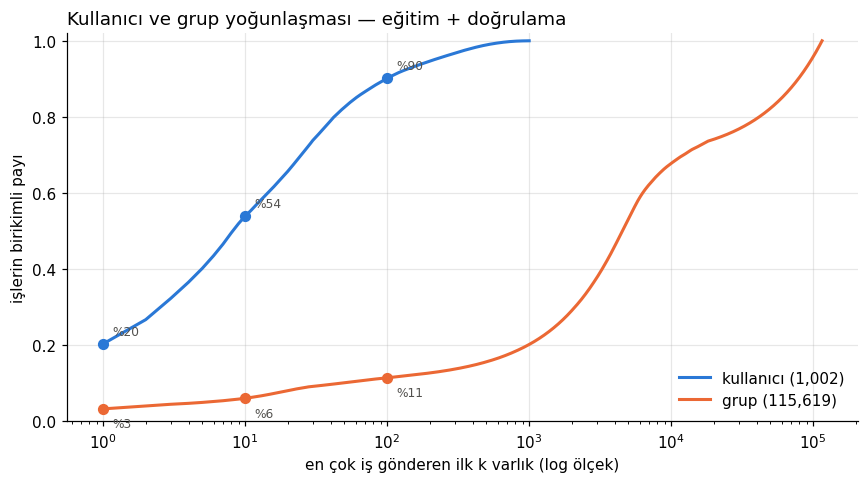

   entity      n  top1_%  top10_%  top100_%  singletons
kullanıcı   1002    20.4     53.9      90.1          84
     grup 115619     3.3      6.1      11.5       97618


In [16]:
# F16: concentration of jobs over users and groups (train + validation)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BLUE, ORANGE, INK2 = '#2a78d6', '#eb6834', '#52514e'
u = pd.read_parquet(PROC / 'm1_features.parquet', columns=['job_name', 'user'])
u = u[u.job_name.isin(E.job_name)]
jt = pd.read_parquet(INTERIM / 'pai_job_table.parquet', columns=['job_name', 'inst_id'])
gt = pd.read_parquet(INTERIM / 'pai_group_tag_table.parquet', columns=['inst_id', 'group'])
grp = u[['job_name']].merge(jt, on='job_name', how='left').merge(gt, on='inst_id', how='left')
print(f'jobs {len(u):,} | users {u.user.nunique():,} | groups {grp.group.nunique():,} '
      f'| jobs without group tag {grp.group.isna().sum():,}')

def top_share(keys):
    cnt = keys.value_counts().to_numpy()               # descending
    k = np.arange(1, len(cnt) + 1)
    return k, np.cumsum(cnt) / cnt.sum(), cnt

fig, ax = plt.subplots(figsize=(8, 4.5))
rows = []
for keys, col, name in [(u.user.astype(str), BLUE, 'kullanıcı'), (grp.group.dropna().astype(str), ORANGE, 'grup')]:
    k, s, cnt = top_share(keys)
    ax.plot(k, s, color=col, lw=2, label=f'{name} ({len(k):,})')
    for kk in (1, 10, 100):
        if kk <= len(k):
            ax.scatter([kk], [s[kk - 1]], s=40, color=col, zorder=3)
            ax.annotate(f'%{100*s[kk-1]:.0f}', (kk, s[kk - 1]), textcoords='offset points',
                        xytext=(6, -12 if name == 'grup' else 6), fontsize=8, color=INK2)
    rows.append({'entity': name, 'n': len(k), 'top1_%': 100 * s[0], 'top10_%': 100 * s[min(9, len(k) - 1)],
                 'top100_%': 100 * s[min(99, len(k) - 1)], 'singletons': int((cnt == 1).sum())})
ax.set_xscale('log'); ax.set_ylim(0, 1.02)
ax.set_xlabel('en çok iş gönderen ilk k varlık (log ölçek)'); ax.set_ylabel('işlerin birikimli payı')
ax.legend(loc='lower right', frameon=False)
ax.set_title('Kullanıcı ve grup yoğunlaşması — eğitim + doğrulama', loc='left')
fig.tight_layout()
save_fig(fig, 16, 'user_group_concentration')
plt.show()
conc = pd.DataFrame(rows).round(1)
print(conc.to_string(index=False))
conc.to_csv(DRIVE / 'results/tables/midterm_concentration.csv', index=False)

with group history: 260,656 (70.5%) | Spearman rho = 0.923
saved F17_history_signal.png


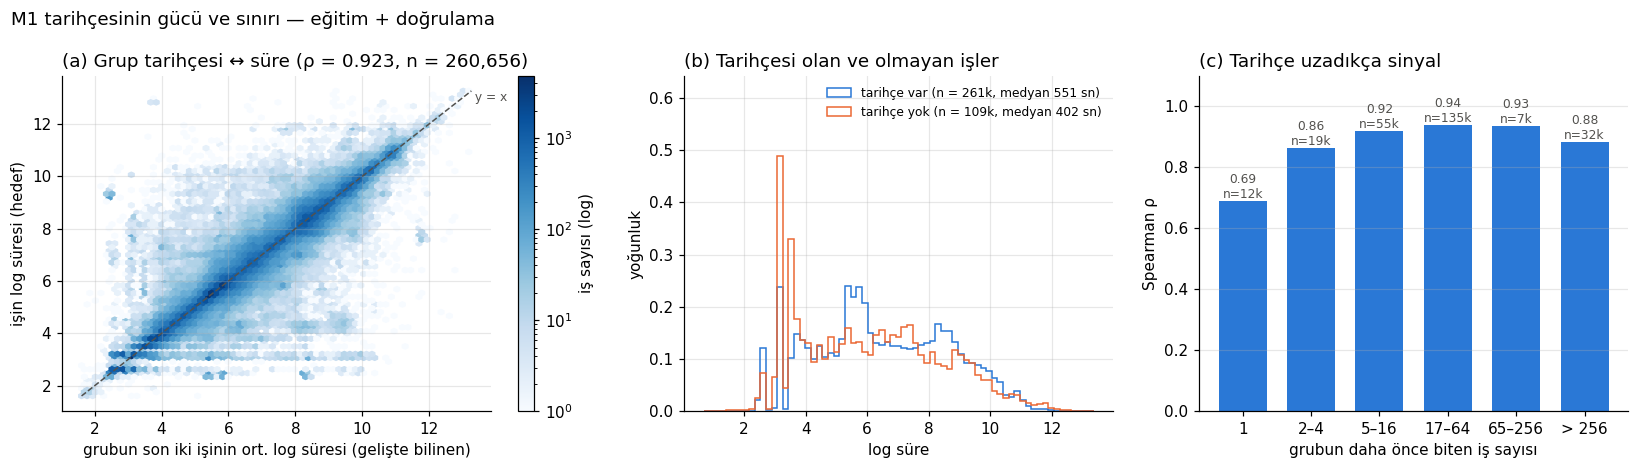

grp_rt_n      n   rho
       1  11999 0.688
     2–4  19414 0.863
    5–16  55374 0.918
   17–64 135153 0.940
  65–256   6751 0.934
   > 256  31965 0.883


In [17]:
# F17: strength and limit of M1 history — group history vs run time (train + validation)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

BLUE, ORANGE, INK2 = '#2a78d6', '#eb6834', '#52514e'
h = pd.read_parquet(PROC / 'm1_features.parquet', columns=['job_name', 'grp_rt_n', 'grp_rt_last2'])
H = E[['job_name', 'run_time']].merge(h, on='job_name')
H['y'] = np.log1p(H.run_time)
has = H.grp_rt_last2.notna()
d = H[has]
rho = spearmanr(d.grp_rt_last2, d.y)[0]
print(f'with group history: {has.sum():,} ({100*has.mean():.1f}%) | Spearman rho = {rho:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={'width_ratios': [1.25, 1, 1]})
ax = axes[0]
hb = ax.hexbin(d.grp_rt_last2, d.y, gridsize=70, bins='log', cmap='Blues', mincnt=1)
lo, hi = np.nanmin([d.y.min(), d.grp_rt_last2.min()]), np.nanmax([d.y.max(), d.grp_rt_last2.max()])
ax.plot([lo, hi], [lo, hi], color=INK2, lw=1, ls='--')
ax.text(hi, hi, ' y = x', fontsize=8, color=INK2, va='top')
ax.set_xlabel('grubun son iki işinin ort. log süresi (gelişte bilinen)'); ax.set_ylabel('işin log süresi (hedef)')
ax.set_title(f'(a) Grup tarihçesi ↔ süre (ρ = {rho:.3f}, n = {has.sum():,})', loc='left')
fig.colorbar(hb, ax=ax, label='iş sayısı (log)')

ax = axes[1]
bins = np.linspace(H.y.min(), H.y.max(), 70)
for mask, col, name in [(has, BLUE, 'tarihçe var'), (~has, ORANGE, 'tarihçe yok')]:
    ax.hist(H.y[mask], bins=bins, density=True, histtype='step', lw=2, color=col,
            label=f'{name} (n = {mask.sum()/1000:.0f}k, medyan {np.expm1(H.y[mask].median()):.0f} sn)')
ax.set_ylim(0, ax.get_ylim()[1] * 1.25)
ax.set_xlabel('log süre'); ax.set_ylabel('yoğunluk'); ax.legend(frameon=False, fontsize=8, loc='upper right')
ax.set_title('(b) Tarihçesi olan ve olmayan işler', loc='left')

ax = axes[2]
edges = [0, 1, 4, 16, 64, 256, np.inf]
labels = ['1', '2–4', '5–16', '17–64', '65–256', '> 256']
d = d.assign(b=pd.cut(d.grp_rt_n, edges, labels=labels))
rows = [(lab, len(g), spearmanr(g.grp_rt_last2, g.y)[0]) for lab, g in d.groupby('b', observed=True) if len(g) > 50]
bars = ax.bar([r[0] for r in rows], [r[2] for r in rows], color=BLUE, width=0.7)
for b_, r in zip(bars, rows):
    ax.text(b_.get_x() + b_.get_width() / 2, r[2], f"{r[2]:.2f}\nn={r[1]/1000:.0f}k" if r[1] >= 1000 else f"{r[2]:.2f}\nn={r[1]}", ha='center', va='bottom', fontsize=8, color=INK2)
ax.set_ylim(0, 1.1); ax.set_xlabel('grubun daha önce biten iş sayısı'); ax.set_ylabel('Spearman ρ')
ax.set_title('(c) Tarihçe uzadıkça sinyal', loc='left'); ax.grid(axis='x', visible=False)

fig.suptitle('M1 tarihçesinin gücü ve sınırı — eğitim + doğrulama', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 17, 'history_signal')
plt.show()
print(pd.DataFrame(rows, columns=['grp_rt_n', 'n', 'rho']).round(3).to_string(index=False))

jobs 358,322 | most common memory request 29.297 GB = 74.0% of jobs
saved F18_request_vs_usage.png


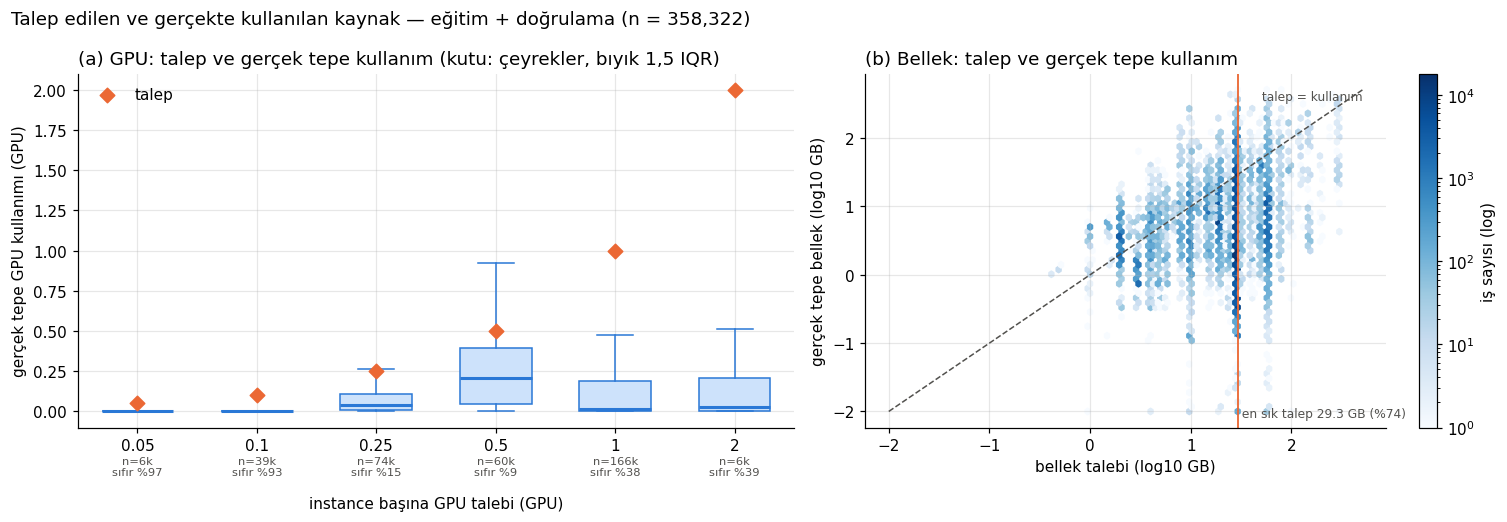

                 group   jobs  median_peak_GB  median_ratio  share_over_request_%
default memory request 265007           3.386         0.116                 7.884
 other memory requests  93315           5.706         0.311                20.207


In [18]:
# F18: requested vs actually used resources (train + validation, jobs with usage)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BLUE, ORANGE, INK2, MUTED = '#2a78d6', '#eb6834', '#52514e', '#898781'
t = pd.read_parquet(PROC / 'targets.parquet',
                    columns=['job_name', 'main_plan_gpu', 'main_plan_mem', 'gpu_util_max', 'max_mem_max'])
t = t[t.job_name.isin(U.job_name)].copy()
t['req_gpu'] = (t.main_plan_gpu / 100).round(2)
t['used_gpu'] = t.gpu_util_max / 100
default_mem = t.main_plan_mem.mode()[0]
is_def = np.isclose(t.main_plan_mem, default_mem)
print(f'jobs {len(t):,} | most common memory request {default_mem:.3f} GB = {100*is_def.mean():.1f}% of jobs')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.1, 1]})

# (a) GPU: used GPU per request level (boxes), request marked
ax = axes[0]
levels = t.req_gpu.value_counts().head(6).index.sort_values()
data = [t.loc[t.req_gpu == L, 'used_gpu'].to_numpy() for L in levels]
ax.boxplot(data, positions=range(len(levels)), widths=0.6, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor='#cde2fb', edgecolor=BLUE), medianprops=dict(color=BLUE, lw=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
ax.scatter(range(len(levels)), levels, marker='D', s=45, color=ORANGE, zorder=3, label='talep')
for i, (L, x) in enumerate(zip(levels, data)):
    ax.text(i, -0.08, f'n={len(x)/1000:.0f}k\nsıfır %{100*(x == 0).mean():.0f}', ha='center', va='top',
            fontsize=7.5, color=INK2, transform=ax.get_xaxis_transform())
ax.set_xticks(range(len(levels)), [f'{L:g}' for L in levels])
ax.set_xlabel('instance başına GPU talebi (GPU)', labelpad=28); ax.set_ylabel('gerçek tepe GPU kullanımı (GPU)')
ax.legend(frameon=False, loc='upper left')
ax.set_title('(a) GPU: talep ve gerçek tepe kullanım (kutu: çeyrekler, bıyık 1,5 IQR)', loc='left')

# (b) Memory: request vs peak, log-log, default request marked
ax = axes[1]
x = np.log10(t.main_plan_mem.clip(lower=0.1)); y = np.log10(t.max_mem_max.clip(lower=0.01))
hb = ax.hexbin(x, y, gridsize=60, bins='log', cmap='Blues', mincnt=1)
lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
ax.plot([lo, hi], [lo, hi], color=INK2, lw=1, ls='--'); ax.text(hi, hi, ' talep = kullanım', fontsize=8, color=INK2, va='top', ha='right')
ax.axvline(np.log10(default_mem), color=ORANGE, lw=1.2)
ax.text(np.log10(default_mem), 0.03, f' en sık talep {default_mem:.1f} GB (%{100*is_def.mean():.0f})',
        transform=ax.get_xaxis_transform(), fontsize=8, color=INK2)
ax.set_xlabel('bellek talebi (log10 GB)'); ax.set_ylabel('gerçek tepe bellek (log10 GB)')
ax.set_title('(b) Bellek: talep ve gerçek tepe kullanım', loc='left')
fig.colorbar(hb, ax=ax, label='iş sayısı (log)')

fig.suptitle(f'Talep edilen ve gerçekte kullanılan kaynak — eğitim + doğrulama (n = {len(t):,})', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 18, 'request_vs_usage')
plt.show()

s = pd.DataFrame({
    'group': ['default memory request', 'other memory requests'],
    'jobs': [is_def.sum(), (~is_def).sum()],
    'median_peak_GB': [t.max_mem_max[is_def].median(), t.max_mem_max[~is_def].median()],
    'median_ratio': [(t.max_mem_max / t.main_plan_mem)[is_def].median(), (t.max_mem_max / t.main_plan_mem)[~is_def].median()],
    'share_over_request_%': [100 * (t.max_mem_max > t.main_plan_mem)[is_def].mean(), 100 * (t.max_mem_max > t.main_plan_mem)[~is_def].mean()]})
print(s.round(3).to_string(index=False))

Spearman correlations between targets:
              log_run_time  gpu_ratio  mem_ratio  gpu_zero
log_run_time         1.000      0.356      0.648    -0.334
gpu_ratio            0.356      1.000      0.365    -0.844
mem_ratio            0.648      0.365      1.000    -0.327
gpu_zero            -0.334     -0.844     -0.327     1.000
saved F23_target_relations.png


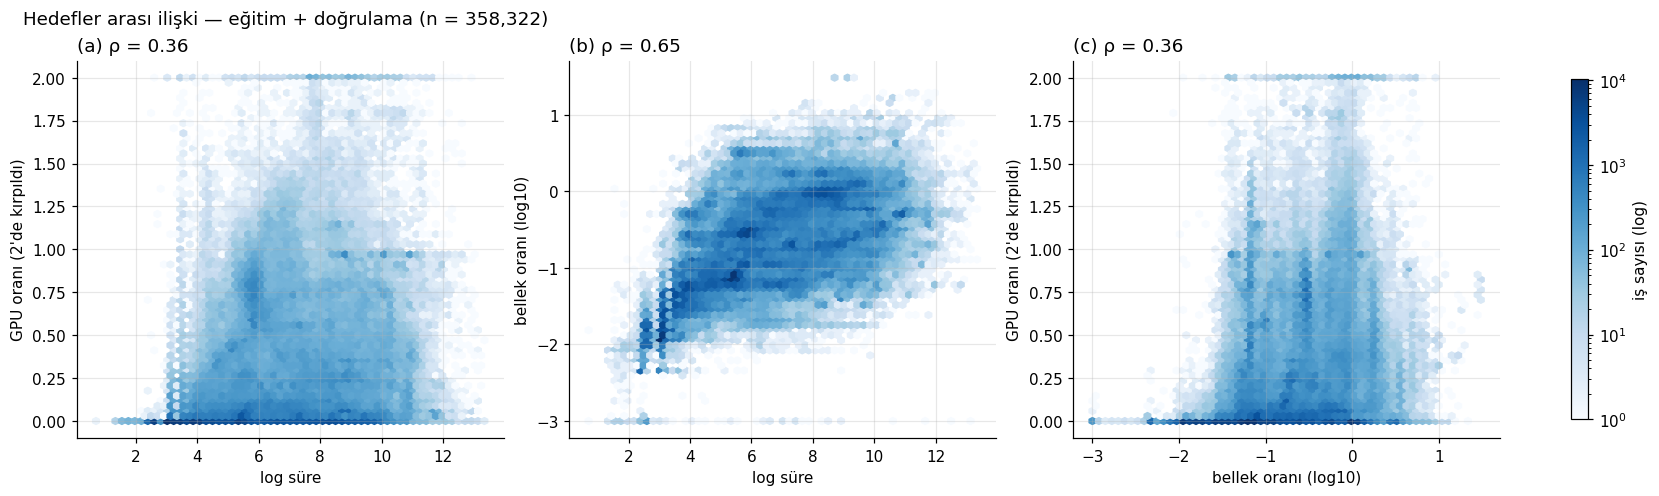


run time (seconds) by GPU-zero status:
                  count    25%    50%     75%
GPU used       233155.0  243.0  878.0  4770.0
GPU ratio = 0  125167.0   32.0  122.0  1695.0


In [19]:
# F23: relations between the three targets (train + validation, jobs with usage) — why multi-task
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

INK2 = '#52514e'
y = pd.read_parquet(PROC / 'targets.parquet', columns=['job_name', 'log_run_time', 'gpu_ratio', 'mem_ratio'])
y = y[y.job_name.isin(U.job_name)].copy()
y['gpu_zero'] = (y.gpu_ratio == 0).astype(float)
y['log_mem'] = np.log10(y.mem_ratio.clip(lower=1e-3))
cols = ['log_run_time', 'gpu_ratio', 'mem_ratio', 'gpu_zero']
R = y[cols].corr(method='spearman')
print('Spearman correlations between targets:'); print(R.round(3).to_string())
R.to_csv(DRIVE / 'results/tables/midterm_target_correlations.csv')

pairs = [('log_run_time', 'gpu_ratio', 'log süre', 'GPU oranı (2\'de kırpıldı)', lambda s: s.clip(upper=2)),
         ('log_run_time', 'log_mem', 'log süre', 'bellek oranı (log10)', lambda s: s),
         ('log_mem', 'gpu_ratio', 'bellek oranı (log10)', 'GPU oranı (2\'de kırpıldı)', lambda s: s.clip(upper=2))]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), layout='constrained')
for ax, (a, b, la, lb, f), tag in zip(axes, pairs, 'abc'):
    hb = ax.hexbin(y[a], f(y[b]), gridsize=60, bins='log', cmap='Blues', mincnt=1)
    r = spearmanr(y[a], y[b])[0]
    ax.set_xlabel(la); ax.set_ylabel(lb); ax.set_title(f'({tag}) ρ = {r:.2f}', loc='left')
fig.colorbar(hb, ax=axes, label='iş sayısı (log)', shrink=0.9)
fig.suptitle(f'Hedefler arası ilişki — eğitim + doğrulama (n = {len(y):,})', x=0.01, ha='left', fontsize=12)
save_fig(fig, 23, 'target_relations')
plt.show()

# Run time by GPU-zero status: are idle-GPU jobs shorter?
g = y.groupby('gpu_zero').log_run_time.describe(percentiles=[.25, .5, .75])[['count', '25%', '50%', '75%']]
g[['25%', '50%', '75%']] = np.expm1(g[['25%', '50%', '75%']]).round(0)
g.index = ['GPU used', 'GPU ratio = 0']
print('\nrun time (seconds) by GPU-zero status:'); print(g.to_string())

saved F05_m2_channel_distributions.png


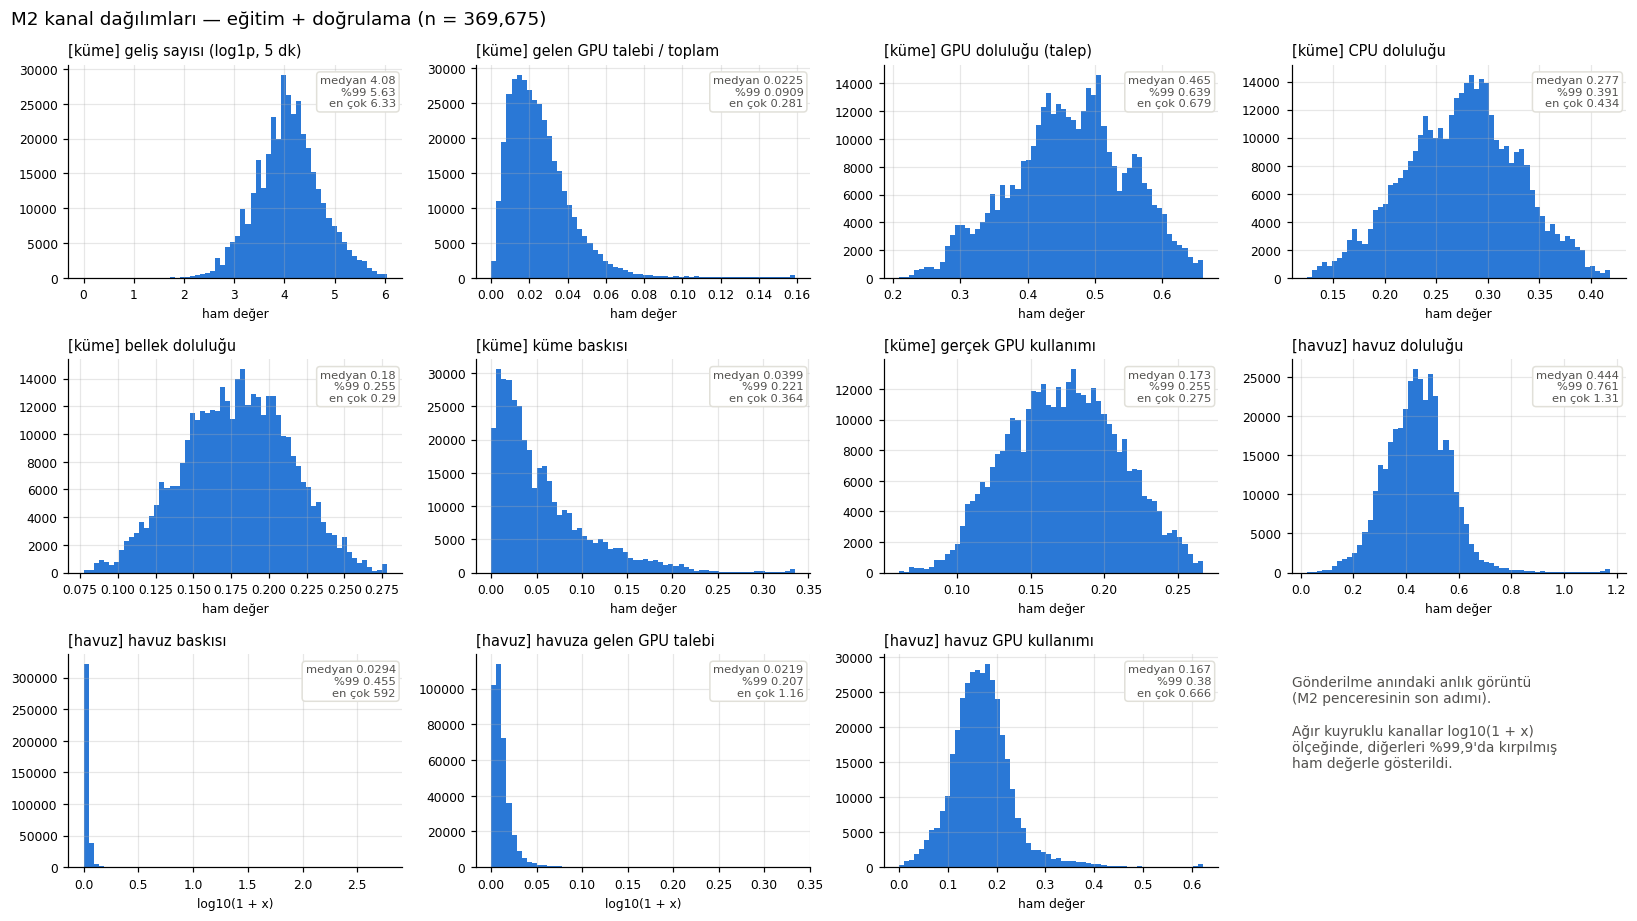

In [20]:
# F05: M2 snapshot channel distributions at submission (train + validation), raw values
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BLUE, INK2 = '#2a78d6', '#52514e'
CH = ['arr_count', 'arr_gpu', 'occ_gpu', 'occ_cpu', 'occ_mem', 'pressure', 'use_gpu',
      'pool_occ', 'pool_pressure', 'pool_arr_gpu', 'pool_use_gpu']
NAMES = {'arr_count': 'geliş sayısı (log1p, 5 dk)', 'arr_gpu': 'gelen GPU talebi / toplam',
         'occ_gpu': 'GPU doluluğu (talep)', 'occ_cpu': 'CPU doluluğu', 'occ_mem': 'bellek doluluğu',
         'pressure': 'küme baskısı', 'use_gpu': 'gerçek GPU kullanımı',
         'pool_occ': 'havuz doluluğu', 'pool_pressure': 'havuz baskısı', 'pool_arr_gpu': 'havuza gelen GPU talebi',
         'pool_use_gpu': 'havuz GPU kullanımı'}
S = pd.read_parquet(PROC / 'm2_snapshots.parquet', columns=['job_name'] + CH)
S = S[S.job_name.isin(E.job_name)]

fig, axes = plt.subplots(3, 4, figsize=(15, 8.5))
for ax, c in zip(axes.flat, CH):
    v = S[c].to_numpy()
    q99 = np.quantile(v, 0.99)
    heavy = v.max() > 5 * q99 and v.max() > 1        # very heavy tail -> show log10(1 + x)
    x = np.log10(1 + v) if heavy else np.clip(v, None, np.quantile(v, 0.999))
    ax.hist(x, bins=60, color=BLUE)
    ax.set_title(('[küme] ' if not c.startswith('pool') else '[havuz] ') + NAMES[c], loc='left', fontsize=9.5)
    ax.text(0.98, 0.95, f'medyan {np.median(v):.3g}\n%99 {q99:.3g}\nen çok {v.max():.3g}', transform=ax.transAxes,
            ha='right', va='top', fontsize=7.5, color=INK2, bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#e1e0d9'))
    ax.set_xlabel('log10(1 + x)' if heavy else 'ham değer', fontsize=8); ax.tick_params(labelsize=8)
axes.flat[-1].axis('off')
axes.flat[-1].text(0, 0.9, 'Gönderilme anındaki anlık görüntü\n(M2 penceresinin son adımı).\n\n'
                   'Ağır kuyruklu kanallar log10(1 + x)\nölçeğinde, diğerleri %99,9\'da kırpılmış\nham değerle gösterildi.',
                   va='top', fontsize=9, color=INK2)
fig.suptitle(f'M2 kanal dağılımları — eğitim + doğrulama (n = {len(S):,})', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 5, 'm2_channel_distributions')
plt.show()

             jobs  gpu_zero_pct  gpu_ratio_median  mem_ratio_median  coverage_median  n_sensor_median
dur                                                                                                  
< 20 sn      9310        98.829             0.000             0.013              1.0              1.0
20–60 sn    53343        74.793             0.000             0.031              1.0              1.0
1–5 dk      83546        31.482             0.028             0.086              1.0              1.0
5–30 dk     91966        20.607             0.140             0.283              1.0              1.0
30 dk–2 sa  64671        31.223             0.077             0.554              1.0              1.0
2–12 sa     47656        21.641             0.159             0.484              1.0              1.0
> 12 sa      7830         3.972             0.218             0.514              1.0              1.0
saved F12_label_quality_by_duration.png


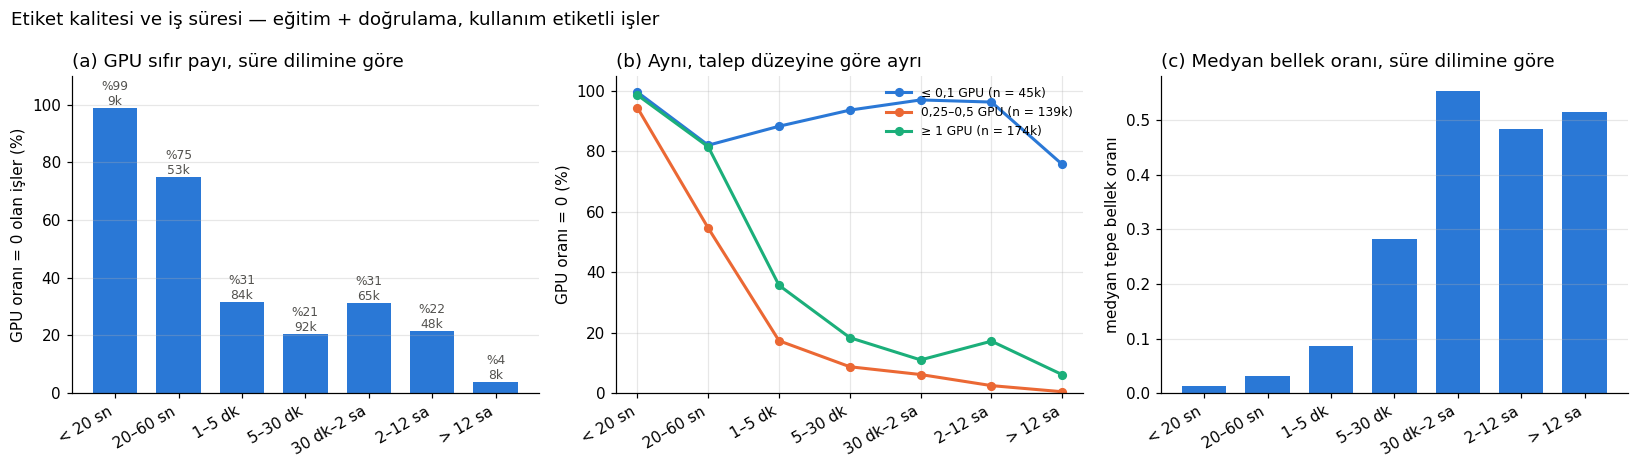

In [21]:
# F12 (part 1): label quality vs run time — is "GPU ratio = 0" real idleness or a short-job measurement artefact?
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, INK2 = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'
q = pd.read_parquet(PROC / 'targets.parquet',
                    columns=['job_name', 'run_time', 'gpu_ratio', 'mem_ratio', 'main_plan_gpu', 'n_sensor', 'usage_coverage'])
q = q[q.job_name.isin(U.job_name)].copy()
edges = [0, 20, 60, 300, 1800, 7200, 43200, np.inf]
labels = ['< 20 sn', '20–60 sn', '1–5 dk', '5–30 dk', '30 dk–2 sa', '2–12 sa', '> 12 sa']
q['dur'] = pd.cut(q.run_time, edges, labels=labels, right=False)
q['req'] = pd.cut(q.main_plan_gpu / 100, [0, 0.1, 0.5, np.inf], labels=['≤ 0,1 GPU', '0,25–0,5 GPU', '≥ 1 GPU'])
q['zero'] = q.gpu_ratio == 0

T = (q.groupby('dur', observed=True)
       .agg(jobs=('job_name', 'size'), gpu_zero_pct=('zero', 'mean'), gpu_ratio_median=('gpu_ratio', 'median'),
            mem_ratio_median=('mem_ratio', 'median'), coverage_median=('usage_coverage', 'median'),
            n_sensor_median=('n_sensor', 'median')))
T['gpu_zero_pct'] *= 100
print(T.round(3).to_string())
T.to_csv(DRIVE / 'results/tables/midterm_label_quality_by_duration.csv')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
x = np.arange(len(T))
ax = axes[0]
bars = ax.bar(x, T.gpu_zero_pct, color=BLUE, width=0.7)
for b_, v, n in zip(bars, T.gpu_zero_pct, T.jobs):
    ax.text(b_.get_x() + b_.get_width() / 2, v, f'%{v:.0f}\n{n/1000:.0f}k', ha='center', va='bottom', fontsize=8, color=INK2)
ax.set_xticks(x, T.index, rotation=30, ha='right'); ax.set_ylim(0, 110); ax.set_ylabel('GPU oranı = 0 olan işler (%)')
ax.set_title('(a) GPU sıfır payı, süre dilimine göre', loc='left'); ax.grid(axis='x', visible=False)

ax = axes[1]
for (name, g), col in zip(q.groupby('req', observed=True), [BLUE, ORANGE, AQUA]):
    s = 100 * g.groupby('dur', observed=True).zero.mean().reindex(labels)
    ax.plot(range(len(labels)), s.values, color=col, lw=2, marker='o', ms=5, label=f'{name} (n = {len(g)/1000:.0f}k)')
ax.set_xticks(range(len(labels)), labels, rotation=30, ha='right'); ax.set_ylim(0, 105)
ax.set_ylabel('GPU oranı = 0 (%)'); ax.legend(frameon=False, fontsize=8, loc='upper right')
ax.set_title('(b) Aynı, talep düzeyine göre ayrı', loc='left')

ax = axes[2]
ax.bar(x, T.mem_ratio_median, color=BLUE, width=0.7)
ax.set_xticks(x, T.index, rotation=30, ha='right'); ax.set_ylabel('medyan tepe bellek oranı')
ax.set_title('(c) Medyan bellek oranı, süre dilimine göre', loc='left'); ax.grid(axis='x', visible=False)

fig.suptitle('Etiket kalitesi ve iş süresi — eğitim + doğrulama, kullanım etiketli işler', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 12, 'label_quality_by_duration')
plt.show()